<a href="https://colab.research.google.com/github/Aditya-Utpat/MyCreationsYet/blob/main/WEC_Intel_REC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 59.9 MB/s eta 0:00:00
Upload your trained .onnx model:


Saving model.onnx to model.onnx

Model loaded successfully!
Input name: input
Input shape: ['batch_size', 3, 96, 96]
Output name: output
Output shape: ['batch_size', 6]

Upload an image of waste to classify:


Saving glass_0002.png to glass_0002.png

Input tensor shape: (1, 3, 96, 96)

       CLASSIFICATION RESULT
Predicted category: glass
Model score: 52.27%

Scores for all categories:
glass       : 52.27%
metal       : 29.96%
trash       : 17.35%
plastic     : 0.40%
paper       : 0.01%
cardboard   : 0.01%


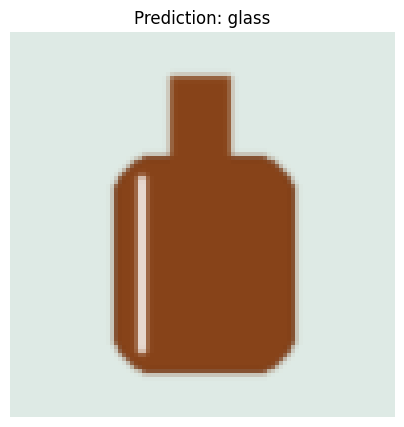

In [ ]:

# ============================================================
# ONNX RUNTIME - WASTE CLASSIFICATION
# Google Colab: Run this entire cell at once
# ============================================================

# 1. Install required libraries
!pip -q install onnxruntime pillow numpy matplotlib

# 2. Import libraries
import os
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

# 3. Upload your ONNX model
print("Upload your trained .onnx model:")
model_upload = files.upload()

model_path = next(
    (name for name in model_upload if name.lower().endswith(".onnx")),
    None
)

if model_path is None:
    raise ValueError("No .onnx model uploaded. Please upload your ONNX model.")

# 4. Load the ONNX model
session = ort.InferenceSession(
    model_path,
    providers=["CPUExecutionProvider"]
)

input_info = session.get_inputs()[0]
output_info = session.get_outputs()[0]

input_name = input_info.name
output_name = output_info.name

print("\nModel loaded successfully!")
print("Input name:", input_name)
print("Input shape:", input_info.shape)
print("Output name:", output_name)
print("Output shape:", output_info.shape)

# 5. Define the waste categories
classes = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

# 6. Upload an image to classify
print("\nUpload an image of waste to classify:")
image_upload = files.upload()

image_path = next(
    (
        name for name in image_upload
        if name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ),
    None
)

if image_path is None:
    raise ValueError("No supported image uploaded.")

# 7. Preprocess the image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((96, 96), Image.Resampling.BILINEAR)

# Convert image to float32 and scale pixel values to [0, 1]
image_array = np.asarray(img_resized, dtype=np.float32) / 255.0

# Apply the same ImageNet normalization used during training
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

image_array = (image_array - mean) / std

# Convert from HWC to CHW and add batch dimension
# HWC: (height, width, channels)
# CHW: (channels, height, width)
input_tensor = np.transpose(image_array, (2, 0, 1))
input_tensor = np.expand_dims(input_tensor, axis=0)
input_tensor = np.ascontiguousarray(input_tensor, dtype=np.float32)

print("\nInput tensor shape:", input_tensor.shape)

# 8. Run inference using ONNX Runtime
outputs = session.run(
    [output_name],
    {input_name: input_tensor}
)

logits = outputs[0][0]

# 9. Convert logits into normalized scores using softmax
shifted_logits = logits - np.max(logits)
exp_scores = np.exp(shifted_logits)
scores = exp_scores / np.sum(exp_scores)

predicted_index = int(np.argmax(scores))
predicted_class = classes[predicted_index]

# 10. Display results
print("\n" + "=" * 40)
print("       CLASSIFICATION RESULT")
print("=" * 40)

print("Predicted category:", predicted_class)
print(f"Model score: {scores[predicted_index] * 100:.2f}%")

print("\nScores for all categories:")
for class_name, score in sorted(
    zip(classes, scores),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{class_name:12s}: {score * 100:.2f}%")

# 11. Display the uploaded image
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Prediction: {predicted_class}")
plt.axis("off")
plt.show()


In [ ]:

# ==============================================================
# ONNX MODEL EVALUATION: WASTE CLASSIFICATION
# Run this entire cell in Google Colab
# ==============================================================

!pip -q install onnxruntime scikit-learn matplotlib pillow pandas

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import onnxruntime as ort

from PIL import Image
from google.colab import files
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --------------------------------------------------------------
# 1. Define class names (must match training order)
# --------------------------------------------------------------
CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# --------------------------------------------------------------
# 2. Upload the ONNX model
# --------------------------------------------------------------
print("UPLOAD YOUR TRAINED ONNX MODEL")
uploaded_model = files.upload()

model_path = next(
    (f for f in uploaded_model if f.lower().endswith(".onnx")),
    None
)

if model_path is None:
    raise ValueError("Please upload a valid .onnx model.")

session = ort.InferenceSession(
    model_path,
    providers=["CPUExecutionProvider"]
)

input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

print("\nModel loaded:", model_path)
print("Input shape:", session.get_inputs()[0].shape)
print("Output shape:", session.get_outputs()[0].shape)

# --------------------------------------------------------------
# 3. Upload dataset ZIP
# --------------------------------------------------------------
print("\nUPLOAD YOUR DATASET AS A ZIP FILE")
uploaded_dataset = files.upload()

zip_path = next(
    (f for f in uploaded_dataset if f.lower().endswith(".zip")),
    None
)

if zip_path is None:
    raise ValueError("Please upload a ZIP file containing your dataset.")

dataset_dir = "/content/waste_test_dataset"
os.makedirs(dataset_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    # Prevent ZIP path traversal when extracting files
    root = os.path.realpath(dataset_dir)
    for member in z.infolist():
        destination = os.path.realpath(
            os.path.join(dataset_dir, member.filename)
        )
        if os.path.commonpath([root, destination]) != root:
            raise ValueError("Unsafe path detected inside ZIP file.")
    z.extractall(dataset_dir)

print("Dataset extracted successfully.")

# --------------------------------------------------------------
# 4. Locate class folders
#    Works if the ZIP contains class folders directly OR
#    contains one parent folder holding the class folders.
# --------------------------------------------------------------
class_dirs = {}

for class_name in CLASSES:
    matches = []
    for current_root, dirs, _ in os.walk(dataset_dir):
        dirs[:] = [
            d for d in dirs
            if not d.startswith("__")
        ]
        for dirname in dirs:
            if dirname.lower() == class_name.lower():
                matches.append(os.path.join(current_root, dirname))

    if len(matches) == 1:
        class_dirs[class_name] = matches[0]
    elif len(matches) == 0:
        raise ValueError(
            f"Could not find a folder named '{class_name}' in the ZIP."
        )
    else:
        raise ValueError(
            f"Found multiple '{class_name}' folders. "
            "Please ZIP only the intended dataset folder."
        )

print("\nDataset folders found:")
for name, path in class_dirs.items():
    print(f"{name:12s} -> {path}")

# --------------------------------------------------------------
# 5. Preprocessing — exactly as in the training script
#    Resize 96x96, RGB, scale to [0,1], ImageNet normalization
# --------------------------------------------------------------
MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
).reshape(1, 1, 3)


def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((96, 96), Image.Resampling.BILINEAR)

    arr = np.asarray(img, dtype=np.float32) / 255.0
    arr = (arr - MEAN) / STD

    # HWC -> CHW, then add batch dimension
    arr = np.transpose(arr, (2, 0, 1))
    arr = np.expand_dims(arr, axis=0)

    return np.ascontiguousarray(arr, dtype=np.float32)


# --------------------------------------------------------------
# 6. Test every image
# --------------------------------------------------------------
true_labels = []
predicted_labels = []
results = []
skipped = []

total_images = 0

for class_name in CLASSES:
    for current_root, _, filenames in os.walk(class_dirs[class_name]):
        for filename in filenames:
            if not filename.lower().endswith(IMAGE_EXTENSIONS):
                continue

            image_path = os.path.join(current_root, filename)
            total_images += 1

            try:
                input_tensor = preprocess_image(image_path)

                output = session.run(
                    [output_name],
                    {input_name: input_tensor}
                )[0]

                logits = np.asarray(output)[0]

                if len(logits) != len(CLASSES):
                    raise ValueError(
                        f"Expected {len(CLASSES)} outputs, "
                        f"but received {len(logits)}."
                    )

                # Stable softmax
                exp_scores = np.exp(logits - np.max(logits))
                scores = exp_scores / np.sum(exp_scores)

                pred_index = int(np.argmax(scores))
                predicted_class = CLASSES[pred_index]
                confidence = float(scores[pred_index])

                true_labels.append(class_name)
                predicted_labels.append(predicted_class)

                results.append({
                    "image": filename,
                    "image_path": image_path,
                    "actual_class": class_name,
                    "predicted_class": predicted_class,
                    "correct": predicted_class == class_name,
                    "top_score_percent": round(confidence * 100, 2),
                    **{
                        f"score_{c}_percent": round(
                            float(scores[i]) * 100, 2
                        )
                        for i, c in enumerate(CLASSES)
                    }
                })

            except Exception as e:
                skipped.append({
                    "image_path": image_path,
                    "error": str(e)
                })

    print(f"Finished processing class: {class_name}")

if not results:
    raise ValueError(
        "No images were successfully tested. "
        "Check your dataset folder structure and image files."
    )

# --------------------------------------------------------------
# 7. Overall accuracy
# --------------------------------------------------------------
accuracy = accuracy_score(true_labels, predicted_labels)

print("\n" + "=" * 60)
print("                 MODEL EVALUATION RESULTS")
print("=" * 60)

print(f"Total image files found:       {total_images}")
print(f"Images successfully tested:    {len(results)}")
print(f"Images skipped due to errors:  {len(skipped)}")
print(f"Correct predictions:           "
      f"{sum(r['correct'] for r in results)}")
print(f"Incorrect predictions:         "
      f"{sum(not r['correct'] for r in results)}")
print(f"\nOVERALL ACCURACY: {accuracy * 100:.2f}%")

# --------------------------------------------------------------
# 8. Precision, recall, F1-score and per-class accuracy
# --------------------------------------------------------------
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    true_labels,
    predicted_labels,
    labels=CLASSES,
    target_names=CLASSES,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=CLASSES
)

print("PER-CLASS ACCURACY:")
for i, class_name in enumerate(CLASSES):
    class_total = int(cm[i].sum())
    class_correct = int(cm[i, i])
    class_accuracy = (
        100 * class_correct / class_total
        if class_total else 0
    )
    print(
        f"{class_name:12s}: {class_accuracy:6.2f}% "
        f"({class_correct}/{class_total})"
    )

# --------------------------------------------------------------
# 9. Plot confusion matrix
#    Rows = actual classes, columns = predicted classes
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix — ONNX Waste Classifier")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# --------------------------------------------------------------
# 10. Save all predictions and incorrect predictions
# --------------------------------------------------------------
results_df = pd.DataFrame(results)

results_csv = "/content/onnx_test_results.csv"
wrong_csv = "/content/onnx_wrong_predictions.csv"

results_df.to_csv(results_csv, index=False)

wrong_df = results_df[~results_df["correct"]].copy()
wrong_df.to_csv(wrong_csv, index=False)

print("\nIncorrect prediction examples:")
if len(wrong_df):
    print(
        wrong_df[
            ["image", "actual_class", "predicted_class",
             "top_score_percent"]
        ].head(20).to_string(index=False)
    )
else:
    print("No incorrect predictions!")

if skipped:
    skipped_df = pd.DataFrame(skipped)
    skipped_csv = "/content/onnx_skipped_images.csv"
    skipped_df.to_csv(skipped_csv, index=False)
    print(f"\nSkipped-image log saved to: {skipped_csv}")

print("\nCSV files saved:")
print(results_csv)
print(wrong_csv)

# --------------------------------------------------------------
# 11. Download the evaluation results
# --------------------------------------------------------------
print("\nDownloading the full results CSV...")
files.download(results_csv)

if len(wrong_df):
    print("Downloading the incorrect predictions CSV...")
    files.download(wrong_csv)

print("\nEvaluation complete!")


UPLOAD YOUR TRAINED ONNX MODEL


KeyboardInterrupt: 

In [ ]:
!pip -q install onnxruntime psutil scikit-learn pandas matplotlib seaborn pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 36.2 MB/s eta 0:00:00


In [ ]:

# ============================================================
# ECOSORT ONNX MODEL: ACCURACY + CPU + RAM + TIMING BENCHMARK
# Google Colab | Single-image (batch size = 1) inference
# ============================================================

import os
import time
import json
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import onnxruntime as ort

from PIL import Image
from pathlib import Path
from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# -------------------- 1. MOUNT GOOGLE DRIVE --------------------

drive.mount("/content/drive")

# CHANGE THESE TWO PATHS TO MATCH YOUR GOOGLE DRIVE
MODEL_PATH = "/content/drive/MyDrive/EcoSort/model.onnx"
DATASET_PATH = "/content/drive/MyDrive/EcoSort/test_data"

OUTPUT_DIR = "/content/benchmark_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -------------------- 2. MODEL CONFIGURATION -------------------

CLASS_NAMES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

IMAGE_SIZE = (96, 96)

# These values match your previous training script.
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"ONNX model not found: {MODEL_PATH}")

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_PATH}")

# Use CPU explicitly for CPU benchmarking.
# This avoids accidentally benchmarking a GPU execution provider.
session_options = ort.SessionOptions()
session_options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

session = ort.InferenceSession(
    MODEL_PATH,
    sess_options=session_options,
    providers=["CPUExecutionProvider"]
)

input_info = session.get_inputs()[0]
output_info = session.get_outputs()[0]

INPUT_NAME = input_info.name
OUTPUT_NAME = output_info.name

print("========== MODEL INFORMATION ==========")
print("Model:", MODEL_PATH)
print("Input name:", INPUT_NAME)
print("Input shape:", input_info.shape)
print("Output name:", OUTPUT_NAME)
print("Output shape:", output_info.shape)
print("Execution provider:", session.get_providers())
print("ONNX Runtime version:", ort.__version__)

# -------------------- 3. IMAGE PREPROCESSING -------------------

def preprocess_image(image_path):
    """
    Returns a normalized RGB image with shape (1, 3, 96, 96).
    Matches the preprocessing used when training your CNN.
    """
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        image = np.asarray(image, dtype=np.float32) / 255.0

    # Normalize each RGB channel.
    image = (image - MEAN) / STD

    # HWC -> CHW, then add batch dimension.
    image = np.transpose(image, (2, 0, 1))
    image = np.expand_dims(image, axis=0)

    return np.ascontiguousarray(image, dtype=np.float32)


# -------------------- 4. FIND TEST IMAGES ----------------------

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = []
true_labels = []

for class_index, class_name in enumerate(CLASS_NAMES):
    class_folder = Path(DATASET_PATH) / class_name

    if not class_folder.is_dir():
        raise FileNotFoundError(
            f"Missing class folder: {class_folder}"
        )

    for image_path in sorted(class_folder.rglob("*")):
        if image_path.is_file() and image_path.suffix.lower() in valid_extensions:
            image_paths.append(str(image_path))
            true_labels.append(class_index)

if len(image_paths) == 0:
    raise ValueError("No supported images found in the dataset.")

print("\n========== DATASET INFORMATION ==========")
print("Total images:", len(image_paths))

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name}: "
        f"{sum(label == i for label in true_labels)} images"
    )

# -------------------- 5. WARM-UP -------------------------------

# Warm-up runs are excluded from latency measurements.
sample_tensor = preprocess_image(image_paths[0])

for _ in range(10):
    session.run(
        [OUTPUT_NAME],
        {INPUT_NAME: sample_tensor}
    )

# Initialize CPU utilization counters.
process = psutil.Process(os.getpid())
process.cpu_percent(interval=None)
psutil.cpu_percent(interval=None)

# -------------------- 6. BENCHMARK -----------------------------

results = []

inference_times = []
preprocessing_times = []
process_cpu_samples = []
system_cpu_samples = []
ram_samples_mb = []

total_start = time.perf_counter()

for index, (image_path, true_label) in enumerate(
    zip(image_paths, true_labels), start=1
):
    # Measure image loading and preprocessing separately.
    preprocess_start = time.perf_counter()
    input_tensor = preprocess_image(image_path)
    preprocessing_time = time.perf_counter() - preprocess_start

    # Time only the ONNX inference call.
    inference_start = time.perf_counter()

    raw_output = session.run(
        [OUTPUT_NAME],
        {INPUT_NAME: input_tensor}
    )[0]

    inference_time = time.perf_counter() - inference_start

    # Your model returns six raw logits.
    logits = np.asarray(raw_output).reshape(-1)

    if len(logits) != len(CLASS_NAMES):
        raise ValueError(
            f"Expected {len(CLASS_NAMES)} output values, "
            f"but received {len(logits)}."
        )

    # Stable softmax for class probabilities.
    shifted_logits = logits - np.max(logits)
    exp_logits = np.exp(shifted_logits)
    probabilities = exp_logits / np.sum(exp_logits)

    predicted_label = int(np.argmax(logits))
    confidence = float(probabilities[predicted_label])

    # Sample resource usage. These samples are approximate.
    process_cpu = process.cpu_percent(interval=None)
    system_cpu = psutil.cpu_percent(interval=None)
    ram_mb = process.memory_info().rss / (1024 ** 2)

    inference_times.append(inference_time)
    preprocessing_times.append(preprocessing_time)
    process_cpu_samples.append(process_cpu)
    system_cpu_samples.append(system_cpu)
    ram_samples_mb.append(ram_mb)

    row = {
        "image": os.path.relpath(image_path, DATASET_PATH),
        "actual_class": CLASS_NAMES[true_label],
        "predicted_class": CLASS_NAMES[predicted_label],
        "correct": predicted_label == true_label,
        "confidence_percent": round(confidence * 100, 4),
        "preprocessing_ms": preprocessing_time * 1000,
        "inference_ms": inference_time * 1000,
        "process_cpu_percent_sample": process_cpu,
        "system_cpu_percent_sample": system_cpu,
        "process_ram_mb": ram_mb
    }

    # Save the predicted probability for every class.
    for class_idx, class_name in enumerate(CLASS_NAMES):
        row[f"prob_{class_name}"] = float(probabilities[class_idx])

    results.append(row)

    if index % 50 == 0 or index == len(image_paths):
        print(f"Processed {index}/{len(image_paths)} images")

total_evaluation_time = time.perf_counter() - total_start

# -------------------- 7. CALCULATE ACCURACY --------------------

df = pd.DataFrame(results)

y_true = np.array(true_labels)
y_pred = np.array([
    CLASS_NAMES.index(name) for name in df["predicted_class"]
])

accuracy = accuracy_score(y_true, y_pred)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

print("\n========== ACCURACY RESULTS ==========")
print(f"Total images tested: {len(df)}")
print(f"Correct predictions: {int(df['correct'].sum())}")
print(f"Incorrect predictions: {(~df['correct']).sum()}")
print(f"Overall accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

# -------------------- 8. PERFORMANCE METRICS -------------------

inf_ms = np.array(inference_times) * 1000
prep_ms = np.array(preprocessing_times) * 1000

metrics = {
    "Model": MODEL_PATH,
    "Dataset": DATASET_PATH,
    "Images tested": len(df),
    "Accuracy percent": accuracy * 100,
    "Mean inference ms per image": np.mean(inf_ms),
    "Median inference ms per image": np.median(inf_ms),
    "P95 inference ms per image": np.percentile(inf_ms, 95),
    "Minimum inference ms": np.min(inf_ms),
    "Maximum inference ms": np.max(inf_ms),
    "Mean preprocessing ms per image": np.mean(prep_ms),
    "Total inference seconds": np.sum(inference_times),
    "Total evaluation wall time seconds": total_evaluation_time,
    "Throughput images per second (inference only)": (
        len(df) / np.sum(inference_times)
    ),
    "Throughput images per second (full evaluation)": (
        len(df) / total_evaluation_time
    ),
    "Mean process CPU percent sample": np.mean(process_cpu_samples),
    "Mean system CPU percent sample": np.mean(system_cpu_samples),
    "Peak sampled process RAM MB": np.max(ram_samples_mb),
    "Mean sampled process RAM MB": np.mean(ram_samples_mb),
    "Execution provider": ", ".join(session.get_providers())
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"]
)

print("\n========== PERFORMANCE BENCHMARK ==========")

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

# -------------------- 9. CONFUSION MATRIX PLOT -----------------

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("ONNX Model Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=150
)
plt.show()

# -------------------- 10. LATENCY DISTRIBUTION ---------------

plt.figure(figsize=(9, 5))
plt.hist(inf_ms, bins=30, edgecolor="black")
plt.xlabel("Inference time per image (milliseconds)")
plt.ylabel("Number of images")
plt.title("ONNX Inference Latency Distribution")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "latency_distribution.png"),
    dpi=150
)
plt.show()

# -------------------- 11. SAVE ALL RESULTS ---------------------

df.to_csv(
    os.path.join(OUTPUT_DIR, "per_image_predictions.csv"),
    index=False
)

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv")
)

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "benchmark_metrics.csv"),
    index=False
)

np.savetxt(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv"),
    cm,
    delimiter=",",
    fmt="%d"
)

with open(
    os.path.join(OUTPUT_DIR, "benchmark_metrics.json"),
    "w"
) as file:
    json.dump(
        {key: (
            float(value) if isinstance(value, (np.floating, np.integer))
            else value
        ) for key, value in metrics.items()},
        file,
        indent=4
    )

print("\n========== BENCHMARK COMPLETE ==========")
print("Results saved in:", OUTPUT_DIR)
print("\nFiles created:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)


MessageError: Error: credential propagation was unsuccessful

STEP 1: Upload your .onnx model file


Saving model.onnx to model.onnx

STEP 2: Upload your dataset .zip file


Saving dataset.zip to dataset.zip
Model: /content/model.onnx
Dataset extracted: /content/test_dataset

MODEL INPUT: ['batch_size', 3, 96, 96]
MODEL OUTPUT: ['batch_size', 6]
EXECUTION PROVIDER: ['CPUExecutionProvider']

DATASET: /content/test_dataset/val
TOTAL IMAGES: 240
cardboard: 40 images
glass: 40 images
metal: 40 images
paper: 40 images
plastic: 40 images
trash: 40 images
Processed 50/240 images
Processed 100/240 images
Processed 150/240 images
Processed 200/240 images
Processed 240/240 images

================ ACCURACY RESULTS ================
Images tested: 240
Correct: 240
Incorrect: 0
OVERALL ACCURACY: 100.00%

Classification report:
              precision    recall  f1-score   support

   cardboard       1.00      1.00      1.00        40
       glass       1.00      1.00      1.00        40
       metal       1.00      1.00      1.00        40
       paper       1.00      1.00      1.00        40
     plastic       1.00      1.00      1.00        40
       trash       1.00

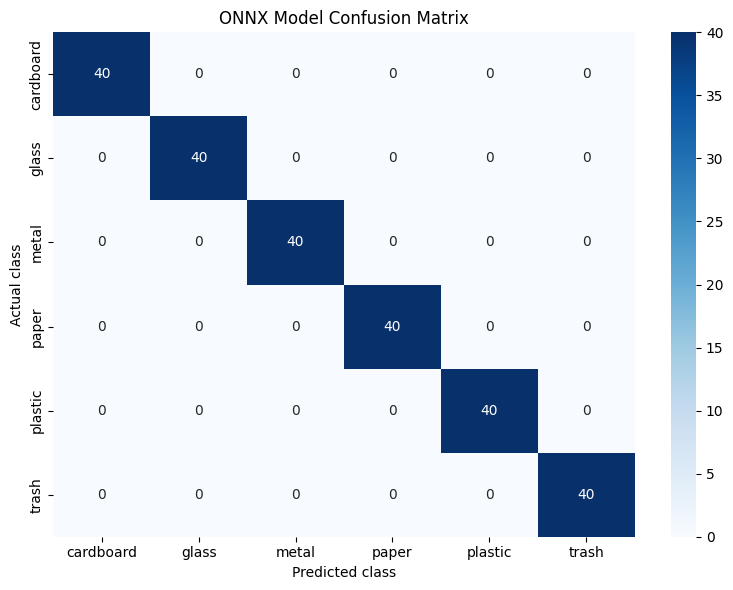

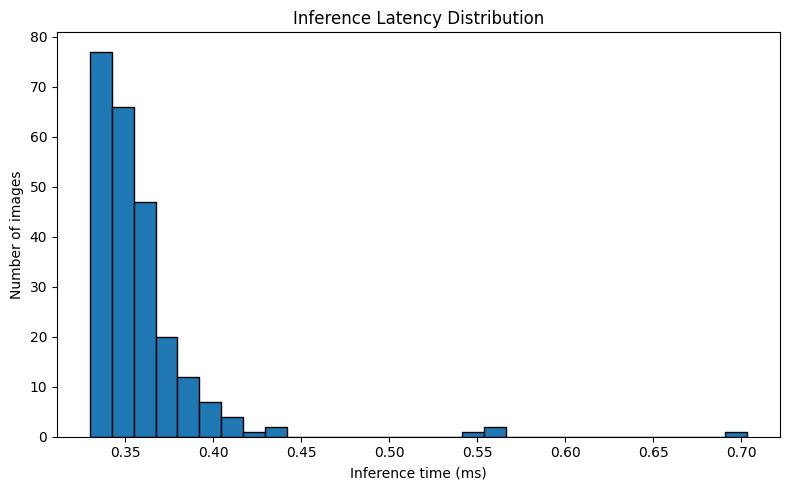


BENCHMARK COMPLETE!
Accuracy: 100.0 %
Mean inference: 0.359 ms/image
Peak sampled RAM: 271.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# ONNX IMAGE CLASSIFIER BENCHMARK - GOOGLE COLAB
# Upload ONNX model + ZIP dataset; no Google Drive required.
# ================================================================

!pip -q install onnxruntime psutil scikit-learn pandas matplotlib seaborn pillow

import os
import time
import json
import shutil
import zipfile
import psutil
import numpy as np
import pandas as pd
import onnxruntime as ort
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from google.colab import files
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ---------------------- CONFIGURATION ----------------------------

CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
IMAGE_SIZE = (96, 96)

# Assumed preprocessing from your previous model.
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

OUTPUT_DIR = "/content/benchmark_results"
DATASET_DIR = "/content/test_dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)

# ---------------------- UPLOAD MODEL -----------------------------

print("STEP 1: Upload your .onnx model file")
uploaded_model = files.upload()
model_files = [f for f in uploaded_model if f.lower().endswith(".onnx")]

if len(model_files) != 1:
    raise ValueError("Upload exactly one .onnx file.")

MODEL_PATH = os.path.abspath(model_files[0])

# ---------------------- UPLOAD DATASET ---------------------------

print("\nSTEP 2: Upload your dataset .zip file")
uploaded_zip = files.upload()
zip_files = [f for f in uploaded_zip if f.lower().endswith(".zip")]

if len(zip_files) != 1:
    raise ValueError("Upload exactly one dataset ZIP file.")

# Safely extract ZIP contents.
with zipfile.ZipFile(zip_files[0], "r") as z:
    for member in z.infolist():
        target = os.path.realpath(os.path.join(DATASET_DIR, member.filename))
        if os.path.commonpath([DATASET_DIR, target]) != DATASET_DIR:
            raise ValueError("Unsafe path detected in ZIP.")
    z.extractall(DATASET_DIR)

print("Model:", MODEL_PATH)
print("Dataset extracted:", DATASET_DIR)

# ---------------------- LOAD ONNX MODEL --------------------------

session_options = ort.SessionOptions()
session_options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

session = ort.InferenceSession(
    MODEL_PATH,
    sess_options=session_options,
    providers=["CPUExecutionProvider"]
)

input_info = session.get_inputs()[0]
output_info = session.get_outputs()[0]
INPUT_NAME = input_info.name
OUTPUT_NAME = output_info.name

print("\nMODEL INPUT:", input_info.shape)
print("MODEL OUTPUT:", output_info.shape)
print("EXECUTION PROVIDER:", session.get_providers())

if len(input_info.shape) != 4:
    raise ValueError("Expected a 4D image input. Check the ONNX model.")

# ---------------------- FIND DATASET FOLDERS ---------------------

root = Path(DATASET_DIR)
candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]
dataset_root = None

for folder in candidates:
    if all((folder / c).is_dir() for c in CLASS_NAMES):
        dataset_root = folder
        break

if dataset_root is None:
    raise ValueError(
        "Could not find all six class folders together: "
        + ", ".join(CLASS_NAMES)
        + ". Ensure the ZIP contains these folders."
    )

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths, true_labels = [], []

for label, class_name in enumerate(CLASS_NAMES):
    for p in sorted((dataset_root / class_name).rglob("*")):
        if p.is_file() and p.suffix.lower() in extensions:
            image_paths.append(str(p))
            true_labels.append(label)

if not image_paths:
    raise ValueError("No supported images were found.")

print("\nDATASET:", dataset_root)
print("TOTAL IMAGES:", len(image_paths))

for i, c in enumerate(CLASS_NAMES):
    print(f"{c}: {true_labels.count(i)} images")

# ---------------------- PREPROCESSING ----------------------------

def preprocess_image(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        x = np.asarray(img, dtype=np.float32) / 255.0

    x = (x - MEAN) / STD
    x = np.transpose(x, (2, 0, 1))
    return np.ascontiguousarray(x[None, ...], dtype=np.float32)

# ---------------------- WARM-UP ----------------------------------

sample = preprocess_image(image_paths[0])
for _ in range(10):
    session.run([OUTPUT_NAME], {INPUT_NAME: sample})

# ---------------------- RUN BENCHMARK ----------------------------

process = psutil.Process(os.getpid())
process.cpu_percent(None)
latencies, prep_times = [], []
cpu_samples, system_cpu_samples, ram_samples = [], [], []
rows = []

evaluation_start = time.perf_counter()

for i, (path, actual) in enumerate(zip(image_paths, true_labels), start=1):
    t0 = time.perf_counter()
    x = preprocess_image(path)
    prep_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    raw = session.run([OUTPUT_NAME], {INPUT_NAME: x})[0]
    inference_time = time.perf_counter() - t0

    logits = np.asarray(raw).reshape(-1)

    if len(logits) != len(CLASS_NAMES):
        raise ValueError(
            f"Model returned {len(logits)} outputs; expected {len(CLASS_NAMES)}."
        )

    # Convert logits to probabilities for confidence reporting.
    exps = np.exp(logits - np.max(logits))
    probabilities = exps / exps.sum()
    predicted = int(np.argmax(logits))

    cpu = process.cpu_percent(None)
    system_cpu = psutil.cpu_percent(None)
    ram_mb = process.memory_info().rss / (1024 ** 2)

    latencies.append(inference_time)
    prep_times.append(prep_time)
    cpu_samples.append(cpu)
    system_cpu_samples.append(system_cpu)
    ram_samples.append(ram_mb)

    row = {
        "image": os.path.relpath(path, dataset_root),
        "actual_class": CLASS_NAMES[actual],
        "predicted_class": CLASS_NAMES[predicted],
        "correct": predicted == actual,
        "confidence_percent": float(probabilities[predicted] * 100),
        "preprocessing_ms": prep_time * 1000,
        "inference_ms": inference_time * 1000,
        "process_cpu_percent_sample": cpu,
        "system_cpu_percent_sample": system_cpu,
        "process_ram_mb": ram_mb
    }

    for j, name in enumerate(CLASS_NAMES):
        row[f"prob_{name}"] = float(probabilities[j])

    rows.append(row)

    if i % 50 == 0 or i == len(image_paths):
        print(f"Processed {i}/{len(image_paths)} images")

total_time = time.perf_counter() - evaluation_start

# ---------------------- ACCURACY METRICS ------------------------

df = pd.DataFrame(rows)
y_true = np.asarray(true_labels)
y_pred = np.array([CLASS_NAMES.index(x) for x in df["predicted_class"]])

accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))

report = classification_report(
    y_true, y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).transpose()

print("\n================ ACCURACY RESULTS ================")
print("Images tested:", len(df))
print("Correct:", int(df["correct"].sum()))
print("Incorrect:", int((~df["correct"]).sum()))
print(f"OVERALL ACCURACY: {accuracy * 100:.2f}%")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nConfusion matrix (rows=actual, columns=predicted):")
print(cm)

# ---------------------- TIMING / RESOURCE METRICS ---------------

lat_ms = np.array(latencies) * 1000
prep_ms = np.array(prep_times) * 1000

metrics = {
    "Model file": os.path.basename(MODEL_PATH),
    "Images tested": len(df),
    "Accuracy percent": accuracy * 100,
    "Mean inference ms/image": np.mean(lat_ms),
    "Median inference ms/image": np.median(lat_ms),
    "P95 inference ms/image": np.percentile(lat_ms, 95),
    "Minimum inference ms": np.min(lat_ms),
    "Maximum inference ms": np.max(lat_ms),
    "Mean preprocessing ms/image": np.mean(prep_ms),
    "Total inference seconds": np.sum(latencies),
    "Total evaluation seconds": total_time,
    "Inference throughput images/sec": len(df) / np.sum(latencies),
    "End-to-end throughput images/sec": len(df) / total_time,
    "Mean sampled process CPU percent": np.mean(cpu_samples),
    "Mean sampled system CPU percent": np.mean(system_cpu_samples),
    "Peak sampled process RAM MB": np.max(ram_samples),
    "Mean sampled process RAM MB": np.mean(ram_samples),
    "ONNX file size MB": os.path.getsize(MODEL_PATH) / (1024 ** 2),
    "Execution provider": ", ".join(session.get_providers())
}

print("\n================ PERFORMANCE RESULTS ================")
for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

# ---------------------- VISUALIZATIONS --------------------------

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("ONNX Model Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(lat_ms, bins=30, edgecolor="black")
plt.xlabel("Inference time (ms)")
plt.ylabel("Number of images")
plt.title("Inference Latency Distribution")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/latency_distribution.png", dpi=150)
plt.show()

# ---------------------- SAVE REPORTS ----------------------------

df.to_csv(f"{OUTPUT_DIR}/per_image_predictions.csv", index=False)
report_df.to_csv(f"{OUTPUT_DIR}/classification_report.csv")

pd.DataFrame(
    list(metrics.items()), columns=["Metric", "Value"]
).to_csv(f"{OUTPUT_DIR}/benchmark_metrics.csv", index=False)

pd.DataFrame(
    cm, index=CLASS_NAMES, columns=CLASS_NAMES
).to_csv(f"{OUTPUT_DIR}/confusion_matrix.csv")

with open(f"{OUTPUT_DIR}/benchmark_metrics.json", "w") as f:
    json.dump(
        {
            k: (
                float(v)
                if isinstance(v, (np.floating, np.integer))
                else v
            )
            for k, v in metrics.items()
        },
        f, indent=2
    )

# ---------------------- DOWNLOAD RESULTS ------------------------

result_zip = shutil.make_archive(
    "/content/onnx_benchmark_results",
    "zip",
    OUTPUT_DIR
)

print("\nBENCHMARK COMPLETE!")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Mean inference:", round(np.mean(lat_ms), 3), "ms/image")
print("Peak sampled RAM:", round(np.max(ram_samples), 2), "MB")
print("Downloading reports ZIP...")

files.download(result_zip)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 1.8 MB/s eta 0:00:00
Upload ONE ONNX model file:


Saving best_trash_classifier_v4.onnx to best_trash_classifier_v4.onnx

Upload ONE dataset ZIP file:


Saving dataset.zip to dataset.zip

Model: /content/best_trash_classifier_v4.onnx
Dataset extracted.

Input shape: ['batch_size', 3, 96, 96]
Output shape: ['batch_size', 6]
Provider: ['CPUExecutionProvider']

Model file size: 0.066 MiB
Stored initializer elements: 12,886
MAC profiler unavailable: The input tensor image_input's shape [batch_size,3,96,96] is not valid, Please set it to a valid shape.

Dataset root: /content/test_dataset/val
Images: 240
cardboard : 40
glass : 40
metal : 40
paper : 40
plastic : 40
trash : 40
Processed 50/240
Processed 100/240
Processed 150/240
Processed 200/240
Processed 240/240

============== ACCURACY ==============
Accuracy: 100.00%
Correct: 240/240
              precision    recall  f1-score   support

   cardboard       1.00      1.00      1.00        40
       glass       1.00      1.00      1.00        40
       metal       1.00      1.00      1.00        40
       paper       1.00      1.00      1.00        40
     plastic       1.00      1.00      

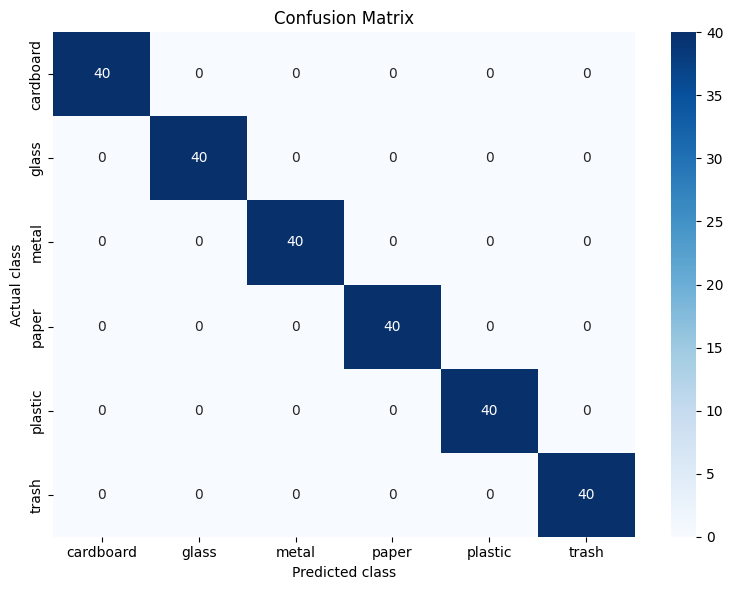

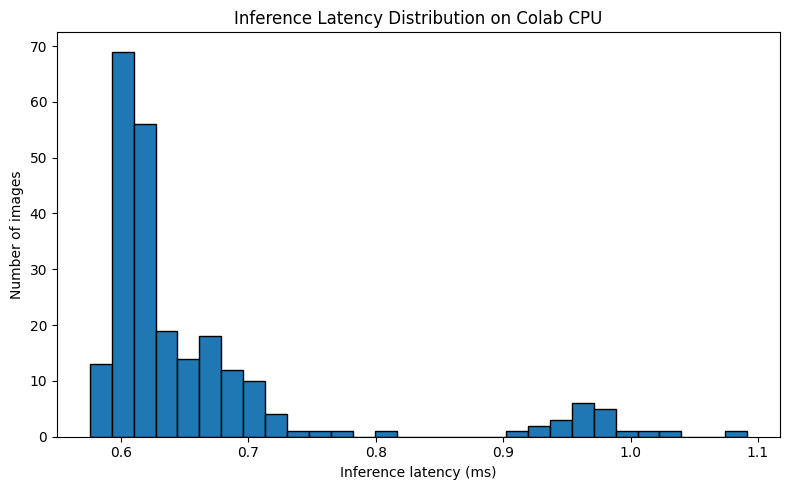


Benchmark completed. Downloading reports...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ================================================================
# ONNX BENCHMARK + RASPBERRY PI 4 MODEL B (2 GB) FEASIBILITY
# Upload model.onnx and dataset.zip directly. No Google Drive.
# ================================================================

!pip -q install onnx onnxruntime onnx-tool psutil scikit-learn pandas matplotlib seaborn pillow

import os, time, json, shutil, zipfile, gc
import numpy as np
import pandas as pd
import psutil
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from google.colab import files
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ---------------- CONFIGURATION ----------------

CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
IMAGE_SIZE = (96, 96)

# Match these values to your training script.
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

RESULTS = "/content/benchmark_results"
DATASET = "/content/test_dataset"
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(DATASET, exist_ok=True)

# Raspberry Pi 4B 2 GB planning assumptions.
PI_RAM_GB = 2.0

# Reserve memory for Raspberry Pi OS, camera, and other services.
# This is a planning budget, not a measured available-memory value.
PI_APP_RAM_BUDGET_MB = 1200

# Optional real-time target. Change if needed.
TARGET_FPS = 10
TARGET_LATENCY_MS = 1000 / TARGET_FPS

# ---------------- UPLOAD FILES ----------------

print("Upload ONE ONNX model file:")
up = files.upload()
models = [x for x in up if x.lower().endswith(".onnx")]
if len(models) != 1:
    raise ValueError("Upload exactly one .onnx file.")
MODEL = os.path.abspath(models[0])

print("\nUpload ONE dataset ZIP file:")
up = files.upload()
zips = [x for x in up if x.lower().endswith(".zip")]
if len(zips) != 1:
    raise ValueError("Upload exactly one dataset ZIP.")

# Safe ZIP extraction.
with zipfile.ZipFile(zips[0]) as z:
    for member in z.infolist():
        target = os.path.realpath(os.path.join(DATASET, member.filename))
        if os.path.commonpath([os.path.realpath(DATASET), target]) != os.path.realpath(DATASET):
            raise ValueError("Unsafe path detected in ZIP.")
    z.extractall(DATASET)

print("\nModel:", MODEL)
print("Dataset extracted.")

# ---------------- LOAD ONNX MODEL ----------------

opts = ort.SessionOptions()
opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

session = ort.InferenceSession(
    MODEL, sess_options=opts,
    providers=["CPUExecutionProvider"]
)

inp = session.get_inputs()[0]
out = session.get_outputs()[0]
INPUT_NAME, OUTPUT_NAME = inp.name, out.name

print("\nInput shape:", inp.shape)
print("Output shape:", out.shape)
print("Provider:", session.get_providers())

if len(inp.shape) != 4:
    raise ValueError("Expected a 4D image input.")

# ---------------- MODEL SIZE / PARAMETER COUNT ----------------

model_bytes = os.path.getsize(MODEL)
model_mb = model_bytes / (1024**2)

onnx_model = onnx.load(MODEL)
initializer_params = sum(
    int(np.prod(t.dims)) for t in onnx_model.graph.initializer
)

print("\nModel file size:", round(model_mb, 3), "MiB")
print("Stored initializer elements:", f"{initializer_params:,}")

# ---------------- ESTIMATE MACs ----------------
# ONNX operator profilers can report different operation counts.
# Only record a MAC value when the API explicitly exposes it.

macs = None
macs_status = "Not reliably available"

try:
    import onnx_tool

    g = onnx_tool.loadmodel(MODEL)
    g.graph.shape_infer()
    g.graph.profile()

    print("\nONNX-Tool profiling ran.")
    print("Inspect its operator/profile summary if printed by this version.")

    # Search common profile result fields for explicitly named MAC counts.
    sources = [g, g.graph]
    for obj in [g, g.graph]:
        for attr in ["profile_result", "profile"]:
            value = getattr(obj, attr, None)
            if isinstance(value, dict):
                sources.append(value)

    for src in sources:
        for key in ["macs", "MACs", "total_macs", "total_mac"]:
            value = src.get(key) if isinstance(src, dict) else getattr(src, key, None)
            if isinstance(value, (int, float, np.integer, np.floating)) and value > 0:
                macs = float(value)
                macs_status = "Explicit MAC field from ONNX-Tool"
                break
        if macs is not None:
            break

    if macs is None:
        print("No unambiguous MAC total exposed by this profiler version.")

except Exception as e:
    print("MAC profiler unavailable:", str(e))

# ---------------- FIND CLASS FOLDERS ----------------

root = Path(DATASET)
candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]
dataset_root = next(
    (p for p in candidates if all((p / c).is_dir() for c in CLASSES)),
    None
)

if dataset_root is None:
    raise ValueError(
        "Could not locate all class folders together: " + str(CLASSES)
    )

exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths, y_true = [], []

for label, cls in enumerate(CLASSES):
    for p in sorted((dataset_root / cls).rglob("*")):
        if p.is_file() and p.suffix.lower() in exts:
            image_paths.append(str(p))
            y_true.append(label)

if not image_paths:
    raise ValueError("No supported images found.")

print("\nDataset root:", dataset_root)
print("Images:", len(image_paths))
for i, cls in enumerate(CLASSES):
    print(cls, ":", y_true.count(i))

# ---------------- IMAGE PREPROCESSING ----------------

def preprocess(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(
            IMAGE_SIZE, Image.Resampling.BILINEAR
        )
        x = np.asarray(im, dtype=np.float32) / 255.0

    x = (x - MEAN) / STD
    x = np.transpose(x, (2, 0, 1))
    return np.ascontiguousarray(x[None, ...], dtype=np.float32)

# ---------------- WARM-UP ----------------

sample = preprocess(image_paths[0])
for _ in range(10):
    session.run([OUTPUT_NAME], {INPUT_NAME: sample})

proc = psutil.Process(os.getpid())
proc.cpu_percent(None)

# ---------------- BENCHMARK ----------------

rows, lat, prep = [], [], []
cpu_samples, sys_cpu_samples, ram_samples = [], [], []

start_all = time.perf_counter()

for i, (path, actual) in enumerate(zip(image_paths, y_true), 1):
    t = time.perf_counter()
    x = preprocess(path)
    prep_s = time.perf_counter() - t

    t = time.perf_counter()
    raw = session.run([OUTPUT_NAME], {INPUT_NAME: x})[0]
    infer_s = time.perf_counter() - t

    logits = np.asarray(raw).reshape(-1)
    if len(logits) != len(CLASSES):
        raise ValueError(
            f"Expected {len(CLASSES)} outputs; received {len(logits)}."
        )

    exp = np.exp(logits - np.max(logits))
    prob = exp / exp.sum()
    pred = int(np.argmax(logits))

    cpu = proc.cpu_percent(None)
    sys_cpu = psutil.cpu_percent(None)
    ram = proc.memory_info().rss / (1024**2)

    lat.append(infer_s)
    prep.append(prep_s)
    cpu_samples.append(cpu)
    sys_cpu_samples.append(sys_cpu)
    ram_samples.append(ram)

    row = {
        "image": os.path.relpath(path, dataset_root),
        "actual_class": CLASSES[actual],
        "predicted_class": CLASSES[pred],
        "correct": pred == actual,
        "confidence_percent": float(prob[pred] * 100),
        "preprocessing_ms": prep_s * 1000,
        "inference_ms": infer_s * 1000,
        "process_cpu_percent_sample": cpu,
        "system_cpu_percent_sample": sys_cpu,
        "process_ram_mb": ram
    }

    for j, cls in enumerate(CLASSES):
        row["prob_" + cls] = float(prob[j])

    rows.append(row)

    if i % 50 == 0 or i == len(image_paths):
        print(f"Processed {i}/{len(image_paths)}")

total_s = time.perf_counter() - start_all

# ---------------- ACCURACY ----------------

df = pd.DataFrame(rows)
yp = np.array([CLASSES.index(v) for v in df["predicted_class"]])
yt = np.asarray(y_true)

accuracy = accuracy_score(yt, yp)
cm = confusion_matrix(yt, yp, labels=range(len(CLASSES)))

report = classification_report(
    yt, yp, labels=range(len(CLASSES)),
    target_names=CLASSES, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).transpose()

print("\n============== ACCURACY ==============")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Correct: {int(df['correct'].sum())}/{len(df)}")
print(classification_report(
    yt, yp, labels=range(len(CLASSES)),
    target_names=CLASSES, zero_division=0
))

# ---------------- PERFORMANCE ----------------

lat_ms = np.asarray(lat) * 1000
prep_ms = np.asarray(prep) * 1000

metrics = {
    "Model file": os.path.basename(MODEL),
    "Model file MiB": model_mb,
    "Stored initializer elements": initializer_params,
    "Images tested": len(df),
    "Accuracy percent": accuracy * 100,
    "Mean inference ms/image": float(np.mean(lat_ms)),
    "Median inference ms/image": float(np.median(lat_ms)),
    "P95 inference ms/image": float(np.percentile(lat_ms, 95)),
    "Mean preprocessing ms/image": float(np.mean(prep_ms)),
    "Total inference seconds": float(np.sum(lat)),
    "Total evaluation seconds": total_s,
    "Inference images/sec": len(df) / np.sum(lat),
    "End-to-end images/sec": len(df) / total_s,
    "Mean sampled process CPU percent": float(np.mean(cpu_samples)),
    "Mean sampled system CPU percent": float(np.mean(sys_cpu_samples)),
    "Peak sampled process RAM MiB": float(np.max(ram_samples)),
    "Mean sampled process RAM MiB": float(np.mean(ram_samples)),
    "Estimated MACs per image": macs,
    "MAC estimation status": macs_status,
    "Execution provider": ", ".join(session.get_providers())
}

print("\n============== PERFORMANCE ==============")
for k, v in metrics.items():
    print(f"{k}: {v}")

# ---------------- RASPBERRY PI 4B 2 GB FEASIBILITY ----------------
# Colab memory use is NOT the Pi's memory use.
# Model file size is NOT peak runtime memory.
# This is a screening estimate, not a hardware guarantee.

# A rough memory planning allowance:
# 3x model file size for weights/runtime/temporary buffers.
# Actual peak can be lower or much higher depending on operators.
estimated_runtime_mb = 3 * model_mb

# Input tensor size for one float32 96x96 RGB image.
input_tensor_mb = (3 * IMAGE_SIZE[0] * IMAGE_SIZE[1] * 4) / (1024**2)

estimated_working_mb = estimated_runtime_mb + input_tensor_mb

if estimated_working_mb <= PI_APP_RAM_BUDGET_MB:
    ram_screen = "LIKELY FITS by rough size-based screening; verify on the Pi"
else:
    ram_screen = "MEMORY RISK: rough estimate exceeds the app RAM budget"

# Actual Pi latency cannot be derived reliably from Colab timing.
# MACs are not always available, and CPU/operator performance varies.
if macs is not None:
    compute_status = (
        "MAC estimate available, but Pi latency still requires a Pi benchmark."
    )
else:
    compute_status = (
        "Pi latency cannot be estimated reliably because MAC count is unavailable."
    )

pi_report = {
    "Target device": "Raspberry Pi 4 Model B, 2 GB RAM",
    "Physical RAM MiB (nominal)": PI_RAM_GB * 1024,
    "Application RAM planning budget MiB": PI_APP_RAM_BUDGET_MB,
    "ONNX file size MiB": model_mb,
    "Rough runtime memory estimate MiB (3x file size heuristic)": estimated_runtime_mb,
    "One input tensor MiB": input_tensor_mb,
    "Rough working-memory estimate MiB": estimated_working_mb,
    "Preliminary RAM screening": ram_screen,
    "Requested target FPS": TARGET_FPS,
    "Requested latency budget ms": TARGET_LATENCY_MS,
    "Colab P95 inference ms (NOT Pi latency)": float(np.percentile(lat_ms, 95)),
    "Compute feasibility": compute_status,
    "Overall conclusion": (
        "Potentially deployable, but not confirmed. Test on the actual Pi "
        "with the intended camera/input pipeline and monitor peak RAM and latency."
    )
}

print("\n============== RASPBERRY PI 4B (2 GB) SCREENING ==============")
for k, v in pi_report.items():
    print(f"{k}: {v}")

# ---------------- PLOTS ----------------

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{RESULTS}/confusion_matrix.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(lat_ms, bins=30, edgecolor="black")
plt.xlabel("Inference latency (ms)")
plt.ylabel("Number of images")
plt.title("Inference Latency Distribution on Colab CPU")
plt.tight_layout()
plt.savefig(f"{RESULTS}/latency_distribution.png", dpi=150)
plt.show()

# ---------------- SAVE ALL REPORTS ----------------

df.to_csv(f"{RESULTS}/per_image_predictions.csv", index=False)
report_df.to_csv(f"{RESULTS}/classification_report.csv")
pd.DataFrame(list(metrics.items()), columns=["Metric", "Value"]).to_csv(
    f"{RESULTS}/benchmark_metrics.csv", index=False
)
pd.DataFrame(list(pi_report.items()), columns=["Metric", "Value"]).to_csv(
    f"{RESULTS}/raspberry_pi_feasibility.csv", index=False
)
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
    f"{RESULTS}/confusion_matrix.csv"
)

with open(f"{RESULTS}/benchmark_report.json", "w") as f:
    json.dump(
        {"benchmark": metrics, "raspberry_pi_screening": pi_report},
        f, indent=2, default=str
    )

# ---------------- DOWNLOAD RESULTS ----------------

archive = shutil.make_archive(
    "/content/onnx_benchmark_results", "zip", RESULTS
)

print("\nBenchmark completed. Downloading reports...")
files.download(archive)
